In [27]:
%matplotlib inline
from amuse.lab import *
from amuse.ic.fractalcluster import new_fractal_cluster_model
import numpy as np
from amuse.units import nbody_system
from matplotlib import pyplot as plt

In [ ]:
from amuse.ic.kroupa import new_kroupa_mass_distribution

n_stars = 1000
mass_min = 0.01 | units.MSun
mass_max = 100 | units.MSun

masses_kroupa = new_kroupa_mass_distribution(n_stars, mass_min=mass_min, mass_max=mass_max)

In [26]:

# we will look over this & refine it later
fractal_dimension = 2.0

# not sure what this length scale is ? 
length_scale = 1.0 | units.parsec

# why are we setting the mass scale to the sum of all the masses? 
mass_scale = masses_kroupa.sum()

converter = nbody_system.nbody_to_si(mass_scale,  length_scale)

star_cluster = new_fractal_cluster_model(n_stars, fractal_dimension=2.0, convert_nbody=converter) 


print(star_cluster[:5])

star_cluster.mass = masses_kroupa
star_cluster.radius = 0.5 | units.au

star_cluster.move_to_center()

print(star_cluster[:5])

                 key         mass       radius           vx           vy           vz            x            y            z
                   -           kg            m    m * s**-1    m * s**-1    m * s**-1            m            m            m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
18398866183213890673    6.419e+29    0.000e+00    7.165e+02   -4.841e+02    1.321e+02    2.914e+16    1.654e+16    4.160e+16
16778408209096283551    6.419e+29    0.000e+00    7.249e+02   -4.954e+02    1.225e+02    2.636e+16    1.583e+16    4.442e+16
17490499933396640807    6.419e+29    0.000e+00    7.245e+02   -5.050e+02    1.099e+02    2.496e+16    1.374e+16    4.538e+16
12613221661804686112    6.419e+29    0.000e+00    7.156e+02   -4.835e+02    8.036e+01    2.525e+16    1.420e+16    4.396e+16
 5487961528396383160    6.419e+29    0.000e+00    6.084e+02   -5.036e+02    8.282e+01    2.649e+16    1.456e+16    4.341e+16


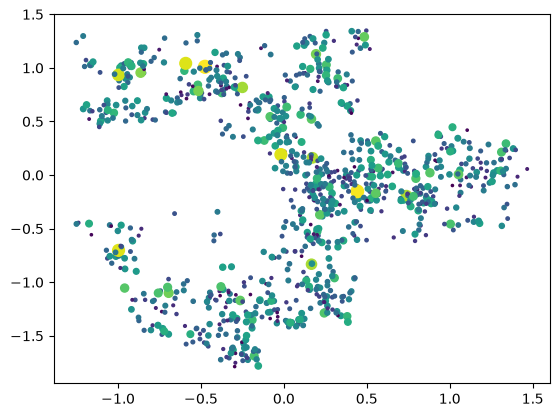

In [25]:
plt.scatter(star_cluster.x.value_in(units.pc),star_cluster.y.value_in(units.pc),
    c=np.log10(star_cluster.mass.value_in(units.MSun)),
    s=25. * np.sqrt(star_cluster.mass.value_in(units.MSun))
)
plt.show()

In [ ]:
from amuse.datamodel import Particles
from amuse.ext.protodisk import ProtoPlanetaryDisk
'''

def make_disk(star, n_disk=1000, r_in=1.0, r_out=100.0, disk_frac=0.01): 
    """Return a gas disk centred on `star`. r_in and r_out are in AU.""" 
    converter = nbody_system.nbody_to_si(star.mass, r_in | units.AU) 
    disk = ProtoPlanetaryDisk(n_disk, convert_nbody=converter, Rmin=1.0, Rmax=r_out / r_in,discfraction=disk_frac).result 

    disk.position += star.position # move disk onto the star 
    disk.velocity += star.velocity 
    disk.host_key = star.key # tag disk particles with their star 
    return disk 

disks = Particles() 
for star in particles_fractal: 
    if star.mass < 2 | units.MSun: 
        disks.add_particles(make_disk(star))
    else: 
        None
'''

/home/z_chu/miniforge3/envs/Amuse-env/lib/python3.14/site-packages/amuse/support/helpers.py:50: FutureWarning: Rmin is deprecated, please use radius_min instead
  warnings.warn(
/home/z_chu/miniforge3/envs/Amuse-env/lib/python3.14/site-packages/amuse/support/helpers.py:50: FutureWarning: Rmax is deprecated, please use radius_max instead
  warnings.warn(


In [ ]:
from amuse.community.seba import Seba
from amuse.ext.protodisk import ProtoPlanetaryDisk
import numpy as np

# this coding snippet will devlop a proto planetary disk for one star which 
# we need to adapt to use it for all 1000 stars! 

disk = ProtoPlanetaryDisk(N=100, densitypower=1.5, Rmin=0.1, Rmax=10, q_out=1, discfraction=0.1,).result
disk.rotate(0, np.pi/6, np.pi/6)


ImportError: Error: seba is not installed, so we cannot use it. To install seba, go to the terminal, make sure that the 'Amuse-env' conda environment is active and that you are in the amuse source directory, then install the code using './setup install amuse-seba' and restart your script or reload the kernel.

In [36]:
from amuse.community.vader.interface import Vader

Vader()